# Prediction with Multi-Layer Perceptrone

<img src="img_notebook/mlp1.png" alt="Descrizione alternativa" width="400" height="300">

### Librerie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import copy


## <span style="color:green"> DR prediction </span>

#### Train 6 curve (better validation err)

Modello MLP per DR:
MLP(
  (layer1): Linear(in_features=10, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)
Epoca [10/200], Training Loss: 11.7764, Validation Loss: 9.6191
Epoca [20/200], Training Loss: 8.6768, Validation Loss: 7.5060
Epoca [30/200], Training Loss: 7.4392, Validation Loss: 6.5867
Epoca [40/200], Training Loss: 6.4368, Validation Loss: 6.2914
Epoca [50/200], Training Loss: 5.4340, Validation Loss: 5.6094
Epoca [60/200], Training Loss: 4.4198, Validation Loss: 5.0870
Epoca [70/200], Training Loss: 3.7192, Validation Loss: 4.6458
Epoca [80/200], Training Loss: 2.9034, Validation Loss: 4.3622
Epoca [90/200], Training Loss: 2.2567, Validation Loss: 4.3277
Epoca [100/200], Training Loss: 1.8323, Validation Loss: 4.2414
Epoca [110/200], Training Loss: 1.4127, Validation Loss: 4.5050
Epoca [120/200], Training Loss: 1.1506, Validation Loss: 4.2100
Ep

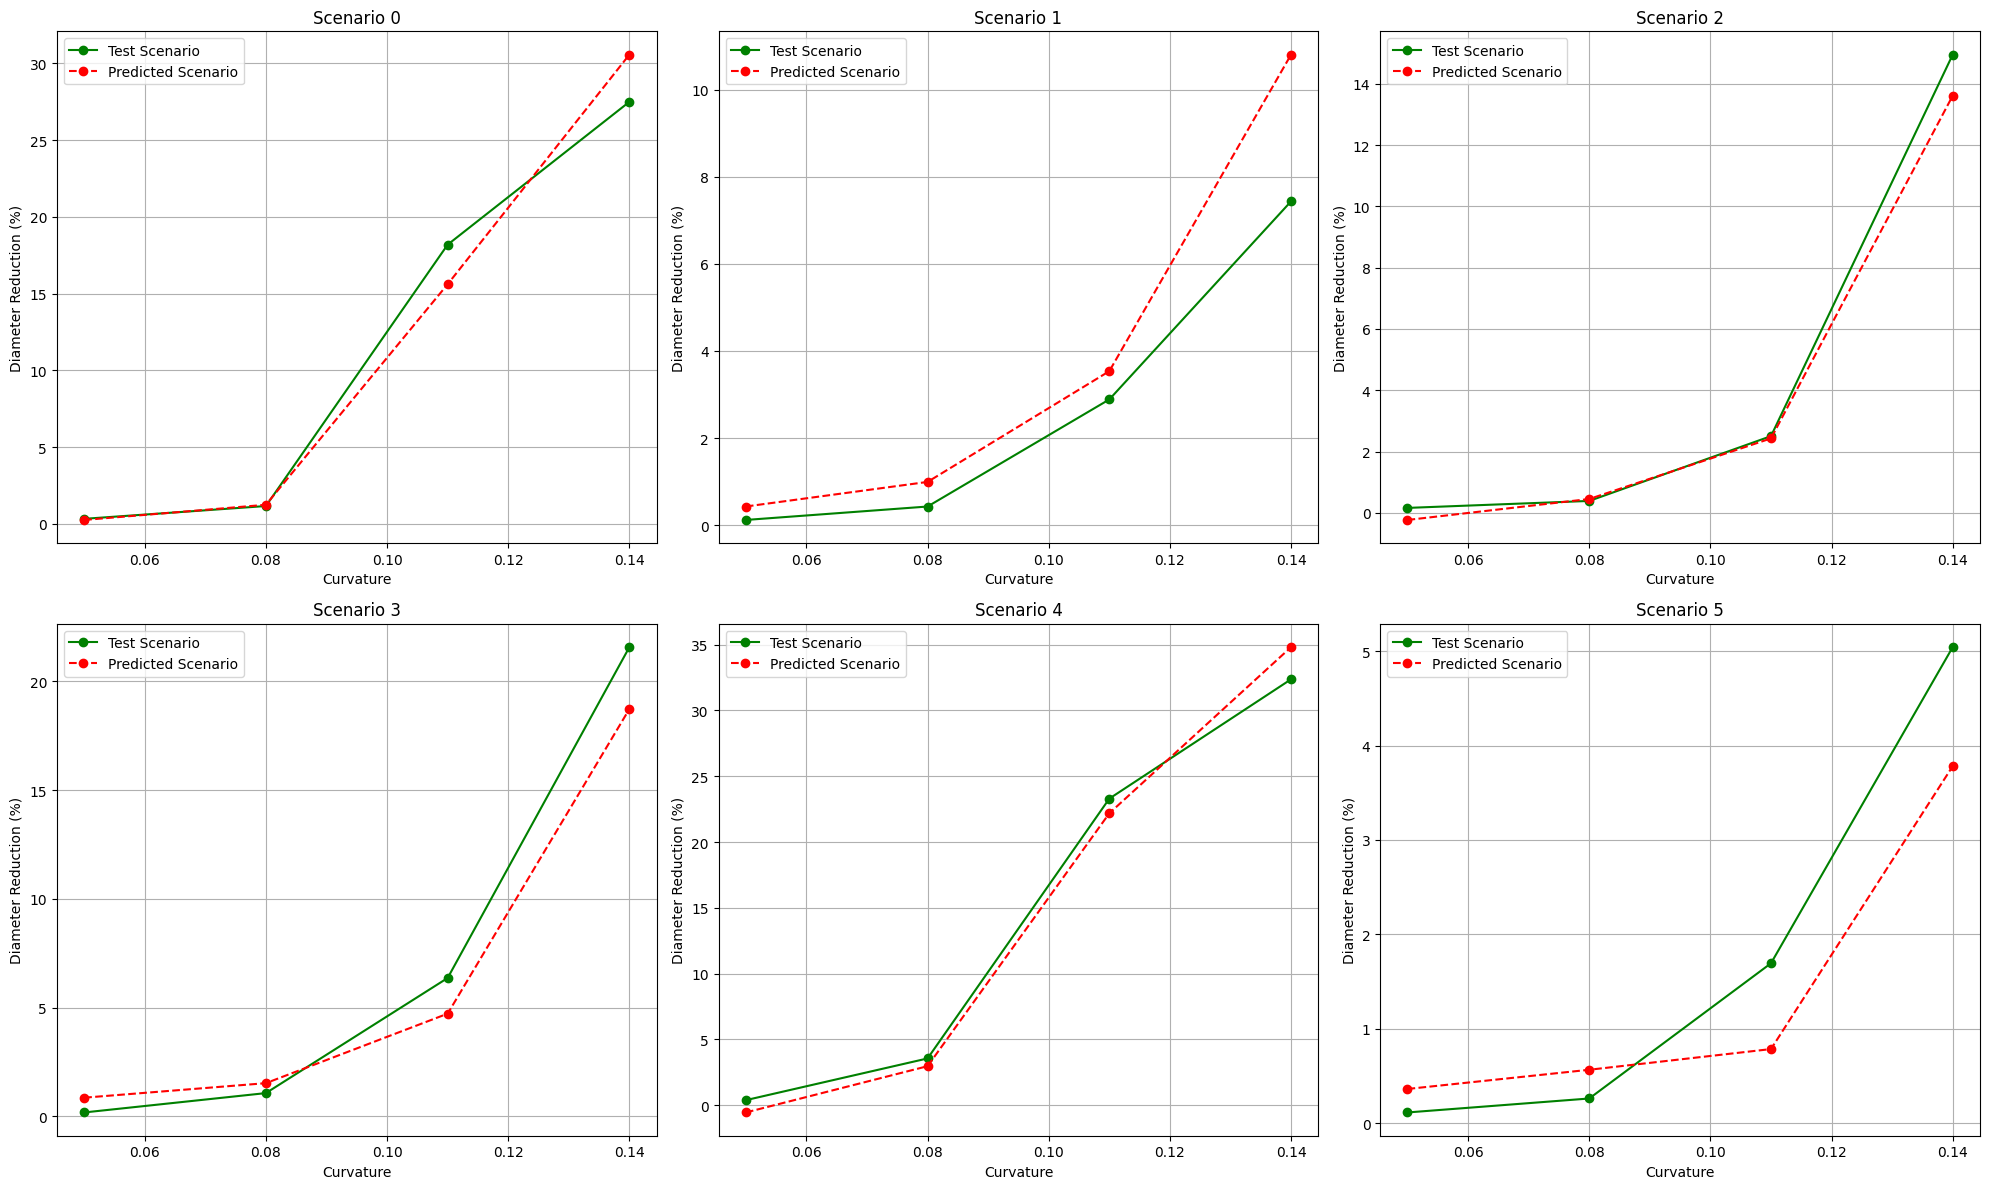

In [11]:
# Caricamento e Preparazione dei Dati
try:
    data_frm = pd.read_csv('AR_DR_results.csv', sep=",", decimal='.')
except FileNotFoundError:
    print("Errore: 'AR_DR_results.csv' non trovato.")
    exit()

X = data_frm.iloc[:, :-2].values.astype(float)
y = data_frm.iloc[:, -1].values.astype(float) # Target DR (%)
n_c = 4
num_scenarios = len(y) // n_c

# Suddivisione basata su scenari
test_scenario_indices = np.arange(6)
train_val_scenario_indices = np.arange(6, num_scenarios)

all_scenario_ids = np.floor(np.arange(len(y)) / n_c)
test_mask = np.isin(all_scenario_ids, test_scenario_indices)
train_val_mask = np.isin(all_scenario_ids, train_val_scenario_indices)

X_train_val, y_train_val = X[train_val_mask], y[train_val_mask]
X_test, y_test = X[test_mask], y[test_mask]

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=42)

# Scalatura delle features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Conversione in tensori PyTorch
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

# Creazione di DataLoader
batch_size = 10
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Costruzione del Modello MLP 
class MLP(nn.Module):
    def __init__(self, input_features):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(input_features, 64)
        self.layer2 = nn.Linear(64, 32)
        self.output_layer = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.output_layer(x)
        return x

# Istanza, loss e ottimizzatore
input_dim = X_train_scaled.shape[1]
model = MLP(input_features=input_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Addestramento e Valutazione
epochs = 200
print(f"Modello MLP per DR:\n{model}")

# Inizializzazione per il salvataggio del modello migliore
best_val_loss = float('inf')
best_model_state = None

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    for inputs, labels in train_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    
    epoch_train_loss = running_train_loss / len(train_loader)
    
    # Calcolo della loss di validazione ad ogni epoca
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            outputs_val = model(inputs_val)
            running_val_loss += criterion(outputs_val, labels_val).item()
            
    epoch_val_loss = running_val_loss / len(val_loader)

    # Logica per salvare il modello migliore
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 10 == 0:
        print(f'Epoca [{epoch+1}/{epochs}], Training Loss: {epoch_train_loss:.4f}, Validation Loss: {epoch_val_loss:.4f}')

# --- Valutazione finale con il modello migliore ---
print("\nCaricamento del modello con il minor errore di validazione per la valutazione finale...")
model.load_state_dict(best_model_state) # <-- MODIFICA: Carica i pesi del modello migliore
model.eval()

y_pred_list = []
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        y_pred_list.append(outputs.cpu().numpy())

y_pred = np.concatenate(y_pred_list).flatten()
y_test_flat = y_test.flatten()

# CALCOLO E STAMPA DELLE METRICHE -------------------------------------------------------------
mse = mean_squared_error(y_test_flat, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_flat, y_pred)
r2 = r2_score(y_test_flat, y_pred)

print("\n--- Metriche di Errore sul Test Set (con modello ottimale) ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("-----------------------------------------")

# Plot per Scenario ---------------------------------------------------------
results_df = pd.DataFrame({
    'scenario': np.floor(np.arange(len(y_test)) / n_c),
    'curvature': X_test[:, -1],
    'y_real': y_test_flat,
    'y_pred': y_pred
})

test_scenarios_to_plot = results_df['scenario'].unique().astype(int)

fig, axes = plt.subplots(2, 3, figsize=(20, 12), squeeze=False)
axes = axes.flatten()

for i, scenario_id in enumerate(test_scenarios_to_plot):
    ax = axes[i]
    scenario_data = results_df[results_df['scenario'] == scenario_id].sort_values(by='curvature')

    ax.plot(scenario_data['curvature'], scenario_data['y_real'], 'o-', color='green', label='Test Scenario')
    ax.plot(scenario_data['curvature'], scenario_data['y_pred'], 'o--', color='red', label='Predicted Scenario')
    
    ax.set_title(f'Scenario {scenario_id}')
    ax.set_xlabel('Curvature')
    ax.set_ylabel('Diameter Reduction (%)')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## <span style="color:magenta"> AR prediction </span>

#### Last model selected

Modello MLP per AR:
MLP(
  (layer1): Linear(in_features=10, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)
Epoca [5/100], Training Loss (last batch): 0.0316, Validation Loss: 0.1449
Epoca [10/100], Training Loss (last batch): 0.0462, Validation Loss: 0.1462
Epoca [15/100], Training Loss (last batch): 0.0600, Validation Loss: 0.0996
Epoca [20/100], Training Loss (last batch): 0.0079, Validation Loss: 0.0659
Epoca [25/100], Training Loss (last batch): 0.0091, Validation Loss: 0.0468
Epoca [30/100], Training Loss (last batch): 0.0052, Validation Loss: 0.0536
Epoca [35/100], Training Loss (last batch): 0.0074, Validation Loss: 0.0365
Epoca [40/100], Training Loss (last batch): 0.0158, Validation Loss: 0.0569
Epoca [45/100], Training Loss (last batch): 0.0116, Validation Loss: 0.0501
Epoca [50/100], Training Loss (last batch): 0.0034, Validation Loss: 0.0408
Epo

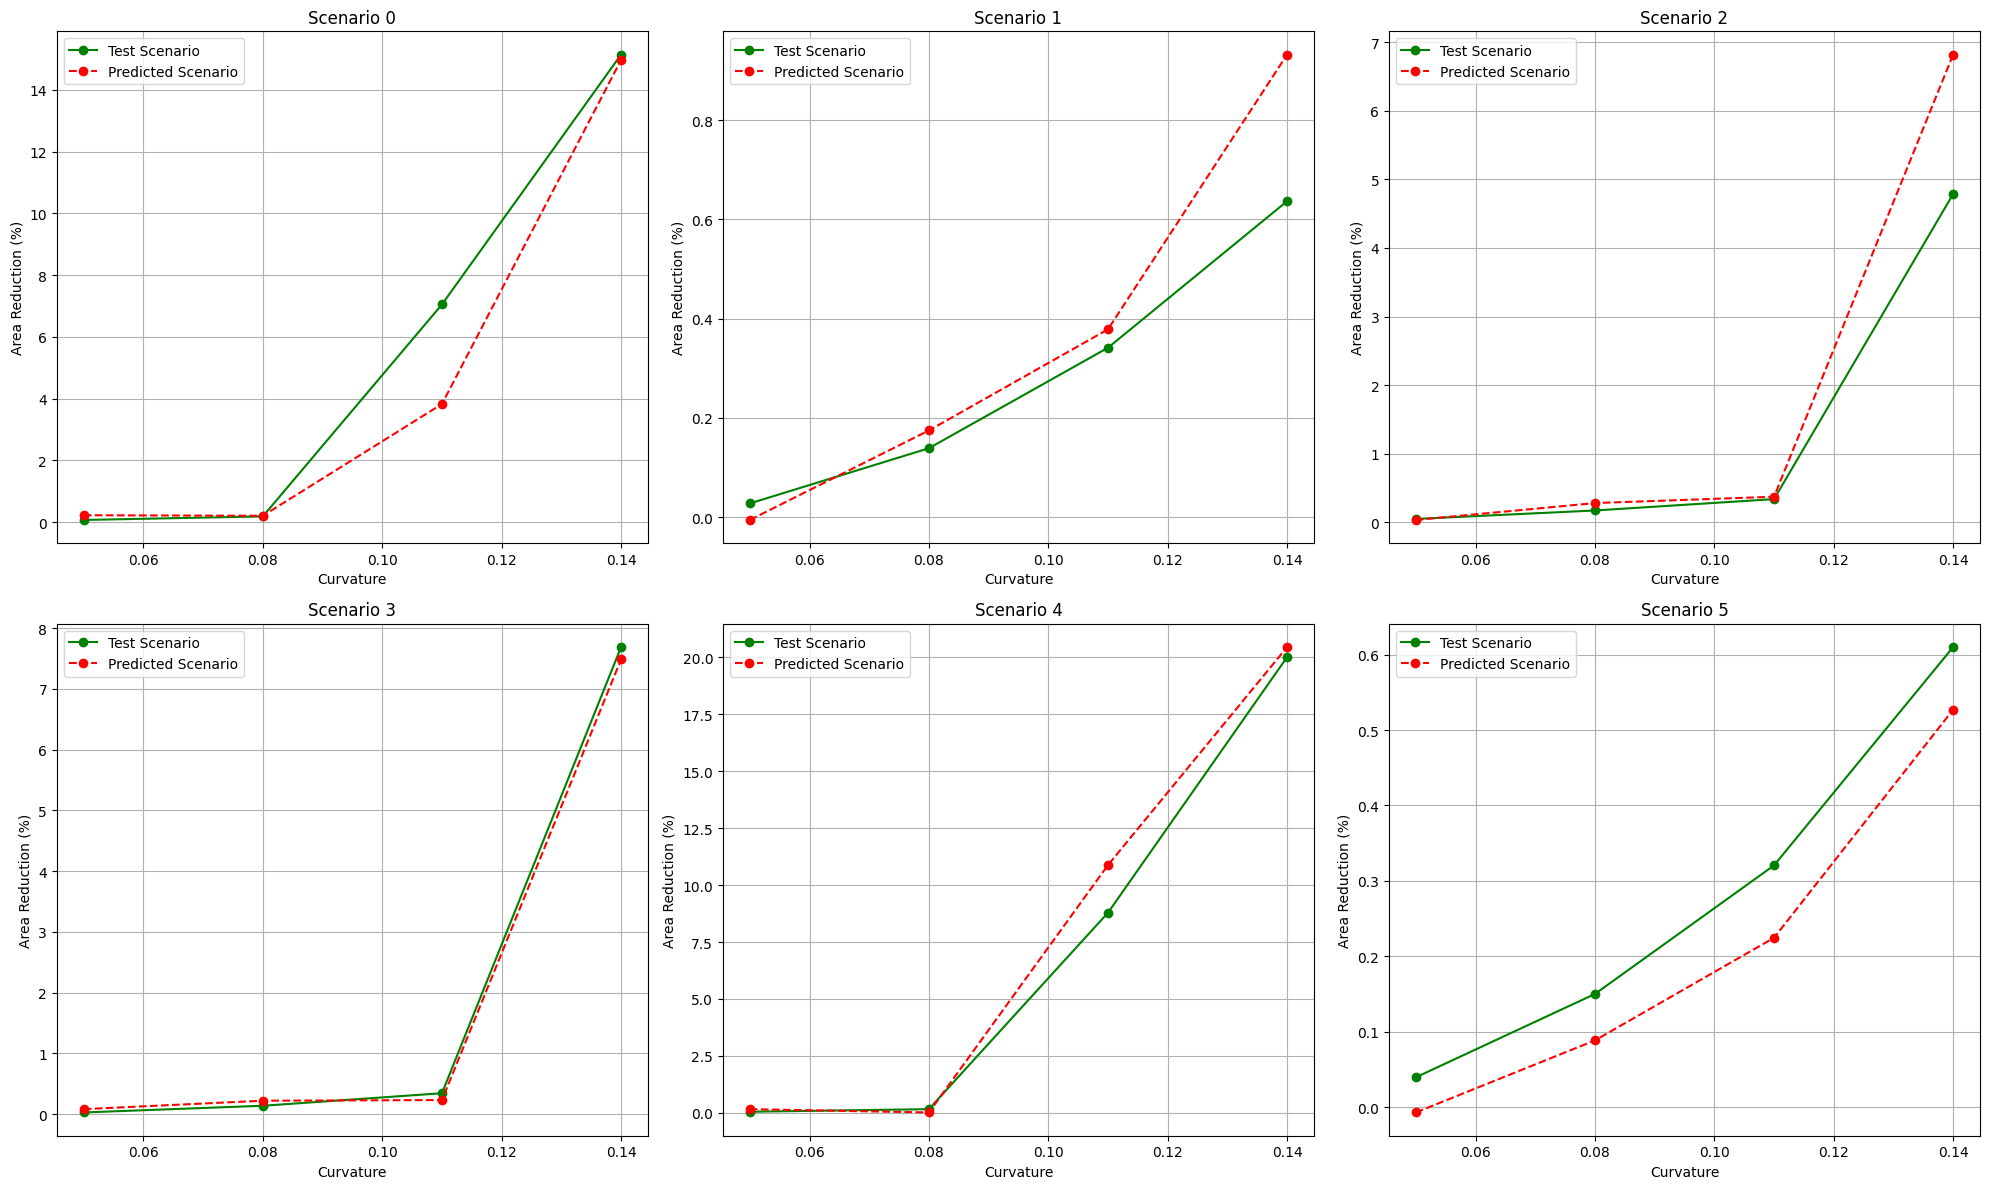

In [3]:
# --- 1. Caricamento e Preparazione dei Dati ---
try:
    data_frm = pd.read_csv('AR_DR_results.csv', sep=",", decimal='.')
except FileNotFoundError:
    print("Errore: 'AR_DR_results.csv' non trovato.")
    exit()

X = data_frm.iloc[:, :-2].values.astype(float)
y = data_frm.iloc[:, -2].values.astype(float) # Target AR (%)
n_c = 4 
num_scenarios = len(y) // n_c

# --- Suddivisione basata su scenari ---
test_scenario_indices = np.arange(6)
train_val_scenario_indices = np.arange(6, num_scenarios)

all_scenario_ids = np.floor(np.arange(len(y)) / n_c)
test_mask = np.isin(all_scenario_ids, test_scenario_indices)
train_val_mask = np.isin(all_scenario_ids, train_val_scenario_indices)

X_train_val, y_train_val = X[train_val_mask], y[train_val_mask]
X_test, y_test = X[test_mask], y[test_mask]

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=42)

# Scalatura delle features e del target
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

# Conversione in tensori PyTorch
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).view(-1, 1)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).view(-1, 1)

# Creazione di DataLoader
batch_size = 10
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# --- 2. Costruzione del Modello MLP ---
class MLP(nn.Module):
    def __init__(self, input_features):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(input_features, 64)
        self.layer2 = nn.Linear(64, 32)
        self.output_layer = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.output_layer(x)
        return x

# Istanza, loss e ottimizzatore
input_dim = X_train_scaled.shape[1]
model = MLP(input_features=input_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

# --- 3. Addestramento e Valutazione ---
epochs = 100
print(f"Modello MLP per AR:\n{model}")

for epoch in range(epochs):
    model.train()
    for inputs, labels in train_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if (epoch + 1) % 5 == 0:
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for inputs_val, labels_val in val_loader:
                outputs_val = model(inputs_val)
                val_loss += criterion(outputs_val, labels_val).item()
        print(f'Epoca [{epoch+1}/{epochs}], Training Loss (last batch): {loss.item():.4f}, Validation Loss: {val_loss/len(val_loader):.4f}')

# Valutazione finale
model.eval()
y_pred_scaled_list = []
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        y_pred_scaled_list.append(outputs.cpu().numpy())

y_pred_scaled = np.concatenate(y_pred_scaled_list)
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()
y_test_flat = y_test.flatten()

# --- CALCOLO E STAMPA DELLE METRICHE ---
mse = mean_squared_error(y_test_flat, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_flat, y_pred)
r2 = r2_score(y_test_flat, y_pred)

print("\\n--- Metriche di Errore sul Test Set ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("-----------------------------------------")


# --- 4. Visualizzazione Corretta per Scenario ---
results_df = pd.DataFrame({
    'scenario': np.floor(np.arange(len(y_test)) / n_c),
    'curvature': X_test[:, -1],
    'y_real': y_test_flat,
    'y_pred': y_pred
})

test_scenarios_to_plot = results_df['scenario'].unique().astype(int)

fig, axes = plt.subplots(2, 3, figsize=(20, 12), squeeze=False)
axes = axes.flatten()

for i, scenario_id in enumerate(test_scenarios_to_plot):
    ax = axes[i]
    scenario_data = results_df[results_df['scenario'] == scenario_id].sort_values(by='curvature')

    ax.plot(scenario_data['curvature'], scenario_data['y_real'], 'o-', color='green', label='Test Scenario')
    ax.plot(scenario_data['curvature'], scenario_data['y_pred'], 'o--', color='red', label='Predicted Scenario')
    
    ax.set_title(f'Scenario {scenario_id}')
    ax.set_xlabel('Curvature')
    ax.set_ylabel('Area Reduction (%)')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

#### Train 6 curve (best validation err)

Modello MLP per AR:
MLP(
  (layer1): Linear(in_features=10, out_features=64, bias=True)
  (layer2): Linear(in_features=64, out_features=32, bias=True)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)
Epoca [10/200], Training Loss: 0.1376, Validation Loss: 0.1488
Epoca [20/200], Training Loss: 0.0817, Validation Loss: 0.1241
Epoca [30/200], Training Loss: 0.0425, Validation Loss: 0.0935
Epoca [40/200], Training Loss: 0.0152, Validation Loss: 0.0702
Epoca [50/200], Training Loss: 0.0084, Validation Loss: 0.0616
Epoca [60/200], Training Loss: 0.0043, Validation Loss: 0.0507
Epoca [70/200], Training Loss: 0.0064, Validation Loss: 0.0500
Epoca [80/200], Training Loss: 0.0056, Validation Loss: 0.0539
Epoca [90/200], Training Loss: 0.0037, Validation Loss: 0.0573
Epoca [100/200], Training Loss: 0.0056, Validation Loss: 0.0611
Epoca [110/200], Training Loss: 0.0013, Validation Loss: 0.0479
Epoca [120/200], Training Loss: 0.0037, Validation Loss: 0.0657
Epo

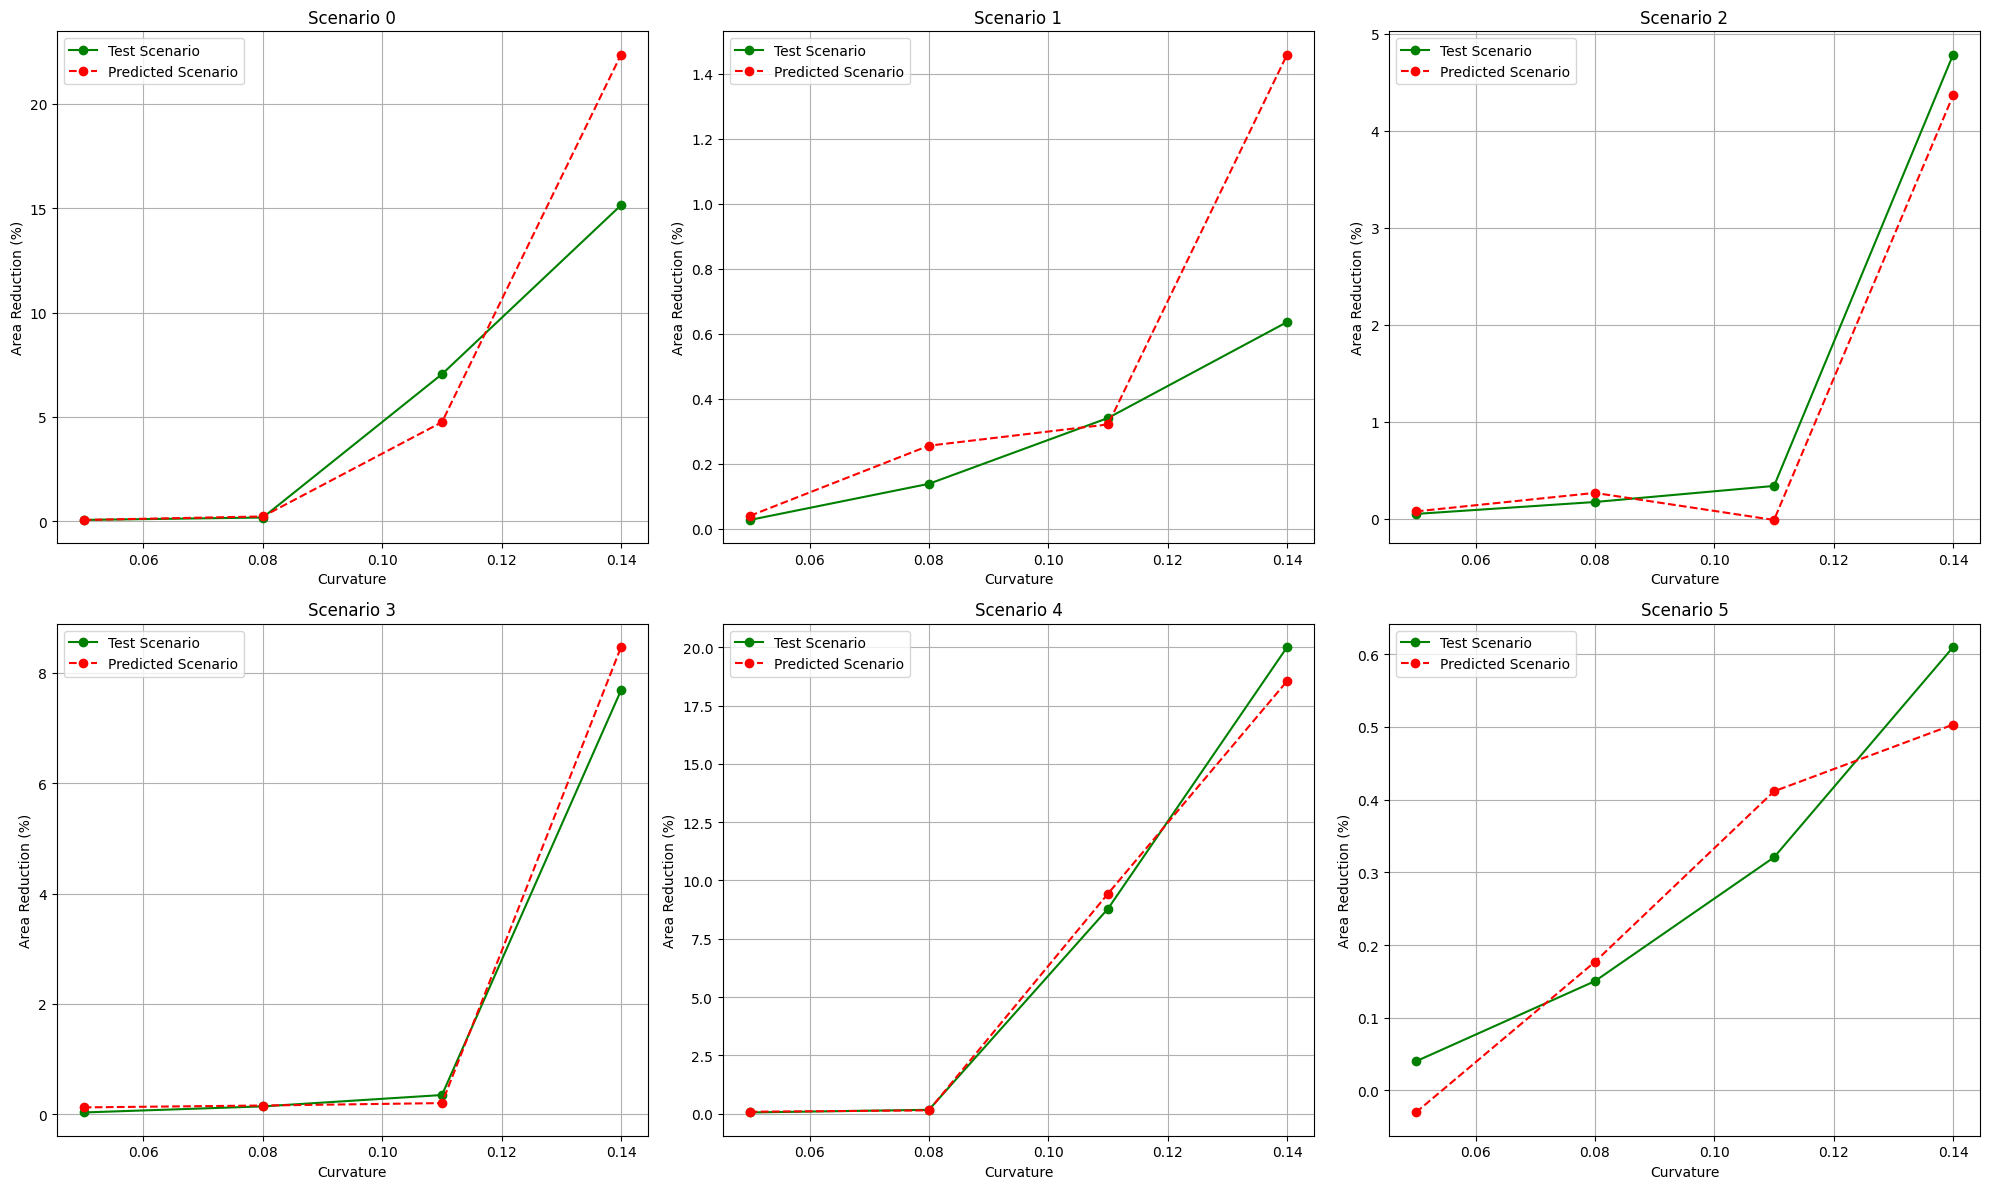

In [10]:
# Caricamento e Preparazione dei Dati
try:
    data_frm = pd.read_csv('AR_DR_results.csv', sep=",", decimal='.')
except FileNotFoundError:
    print("Errore: 'AR_DR_results.csv' non trovato.")
    exit()

X = data_frm.iloc[:, :-2].values.astype(float)
y = data_frm.iloc[:, -2].values.astype(float) # Target AR (%)
n_c = 4 
num_scenarios = len(y) // n_c

# Suddivisione basata su scenari
test_scenario_indices = np.arange(6)
train_val_scenario_indices = np.arange(6, num_scenarios)

all_scenario_ids = np.floor(np.arange(len(y)) / n_c)
test_mask = np.isin(all_scenario_ids, test_scenario_indices)
train_val_mask = np.isin(all_scenario_ids, train_val_scenario_indices)

X_train_val, y_train_val = X[train_val_mask], y[train_val_mask]
X_test, y_test = X[test_mask], y[test_mask]

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=42)

# Scalatura delle features e del target
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled = scaler_X.transform(X_val)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

# Conversione in tensori PyTorch
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).view(-1, 1)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).view(-1, 1)

# Creazione di DataLoader
batch_size = 10
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

# Costruzione del Modello MLP --------------------------------------------------------------
class MLP(nn.Module):
    def __init__(self, input_features):
        super(MLP, self).__init__()
        self.layer1 = nn.Linear(input_features, 64)
        self.layer2 = nn.Linear(64, 32)
        self.output_layer = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.output_layer(x)
        return x

# Istanza, loss e ottimizzatore
input_dim = X_train_scaled.shape[1]
model = MLP(input_features=input_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Addestramento e Valutazione -----------------------------------------
epochs = 200
print(f"Modello MLP per AR:\n{model}")

# Inizializzazione per il salvataggio del modello migliore
best_val_loss = float('inf')
best_model_state = None

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    for inputs, labels in train_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
    
    epoch_train_loss = running_train_loss / len(train_loader)

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            outputs_val = model(inputs_val)
            running_val_loss += criterion(outputs_val, labels_val).item()
            
    epoch_val_loss = running_val_loss / len(val_loader)
    
    # Logica per salvare il modello migliore
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 10 == 0:
        print(f'Epoca [{epoch+1}/{epochs}], Training Loss: {epoch_train_loss:.4f}, Validation Loss: {epoch_val_loss:.4f}')

# -Valutazione finale con il modello migliore --------------------------------------------------------------------
print("\nCaricamento del modello con il minor errore di validazione per la valutazione finale...")
model.load_state_dict(best_model_state) # Carica i pesi del modello migliore
model.eval()

y_pred_scaled_list = []
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        y_pred_scaled_list.append(outputs.cpu().numpy())

y_pred_scaled = np.concatenate(y_pred_scaled_list)
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()
y_test_flat = y_test.flatten()

# CALCOLO E STAMPA DELLE METRICHE ------------------------------------------------------------------------------------
mse = mean_squared_error(y_test_flat, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_flat, y_pred)
r2 = r2_score(y_test_flat, y_pred)

print("\n--- Metriche di Errore sul Test Set (con modello ottimale) ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("-----------------------------------------")

# Visualizzazione per Scenario ------------------------------------------------------------
results_df = pd.DataFrame({
    'scenario': np.floor(np.arange(len(y_test)) / n_c),
    'curvature': X_test[:, -1],
    'y_real': y_test_flat,
    'y_pred': y_pred
})

test_scenarios_to_plot = results_df['scenario'].unique().astype(int)

fig, axes = plt.subplots(2, 3, figsize=(20, 12), squeeze=False)
axes = axes.flatten()

for i, scenario_id in enumerate(test_scenarios_to_plot):
    ax = axes[i]
    scenario_data = results_df[results_df['scenario'] == scenario_id].sort_values(by='curvature')

    ax.plot(scenario_data['curvature'], scenario_data['y_real'], 'o-', color='green', label='Test Scenario')
    ax.plot(scenario_data['curvature'], scenario_data['y_pred'], 'o--', color='red', label='Predicted Scenario')
    
    ax.set_title(f'Scenario {scenario_id}')
    ax.set_xlabel('Curvature')
    ax.set_ylabel('Area Reduction (%)')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

## <span style="color:blue"> Area Profile prediction </span>

### Prerequisiti

In [5]:
# RECUPERO COMBINAZIONI PARAMETRI DoE
data = pd.read_csv('AR_DR_results.csv')

# Definizione dinamica delle feature e dei target
targets = [col for col in data.columns if '(%)' in col]        # I target sono le colonne risultato che contengono '(%)'.
features = [col for col in data.columns if col not in targets] # Le features sono tutte le altre colonne, escludendo i target.

# Stampa di verifica per assicurarsi che le colonne siano state assegnate correttamente
print("Features identificate:", features)
print("Target identificati:", targets)

# Vettori di dati e features
X_data = data[features].to_numpy()
Y_data = data[targets].to_numpy()

n_c = 4

# Values
n_run = len(X_data[:,1])
outer_diameter = X_data[:, 0]
wall_thickness = X_data[:, 1]
axial_load = X_data[:, 2]
ext_press = X_data[:, 3]
young_mod = X_data[:, 4]
poiss_mod = X_data[:, 5]
SY1 = X_data[:, 6]
SY2 = X_data[:, 7]
EP2 = X_data[:, 8]
ovalisation = X_data[:, 9]
curvatures = X_data[:, -1]

## LEGGO CURVATURE
def_A = []
for ii in range(1, n_run+1):  
    mypathfile = 'postProc_out/detailed_tables/detailed_run_' + str(ii).zfill(4) + '_results.csv'
    datafrm = pd.read_csv(mypathfile, sep=",", decimal='.')
    dati = datafrm.values
    xs = dati[:,0]  # ascissa curvilinea
    pipe_abs = xs  # nome alternativo 
    def_A.append(dati[:,2])  # area deformata


Features identificate: ['D_out', 'Wall_Thickness', 'Compression_Force', 'External_Pressure', 'Young Modulus', 'SY1', 'SY2', 'EP2', 'Ovalisation', 'Curvature']
Target identificati: ['AR (%)', 'DR (%)']


In [6]:
# Inizializza gli array
num_samples = X_data.shape[0] // n_c   # numero di scenari
params = np.zeros((num_samples, n_c+1))
dr = np.zeros((num_samples, n_c+1))
ar = np.zeros((num_samples, n_c+1))

# Estrazione di n_c valori per ogni ciclo
for ii in range(num_samples):    
    # Viene aggiunto (0,0) all'inizio in modo automatico
    dr[ii, 1:] = Y_data[ii * n_c:(ii+1) * n_c, -1]  # 4 valori di DR
    ar[ii, 1:] = Y_data[ii * n_c:(ii+1) * n_c, 0]  # 4 valori di AR
    params[ii, 1:] = X_data[ii * n_c:(ii+1) * n_c, -1]  # 4 valori di Curvature

# Verifica
print(f"dimensioni dr = {dr.shape}")
print(f"dimensioni dr = {dr[122]}")

dimensioni dr = (256, 5)
dimensioni dr = [ 0.          0.11776812  1.31750091  7.22414262 21.97339448]


In [7]:
# Riduco i parametri ingresso (si ripetono all'interno del singolo scenario)
#X_red = X_data[::n_c,:-1]  # rimuovo curvatura

a_profiles = np.array(def_A) # trasformo in un numpy array

# Rimuovo gli zeri usati prima, la zero è undeformed
params_ap = params[:, 1:] 

num_samples = a_profiles.shape[0] // n_c  # numero scenari

num_abs = pipe_abs.shape[0]   # numero ascisse curvilinee


### Err Val per miglior modello

Architettura del Modello:
ProfileMLP(
  (network): Sequential(
    (0): Linear(in_features=11, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

Inizio Addestramento...
Epoca [10/100], Training Loss: 183331259.8619, Validation Loss: 296072345.0309
Epoca [20/100], Training Loss: 88167138.9690, Validation Loss: 126715103.7732
Epoca [30/100], Training Loss: 65992958.9284, Validation Loss: 93042452.9098
Epoca [40/100], Training Loss: 44264492.7890, Validation Loss: 59645564.6985
Epoca [50/100], Training Loss: 35049557.1271, Validation Loss: 52770308.7990
Epoca [60/100], Training Loss: 29351291.2973, Validation Loss: 53671405.0309
Epoca [70/100], Training Loss: 25856935.8748, Validation Loss: 52526902.39

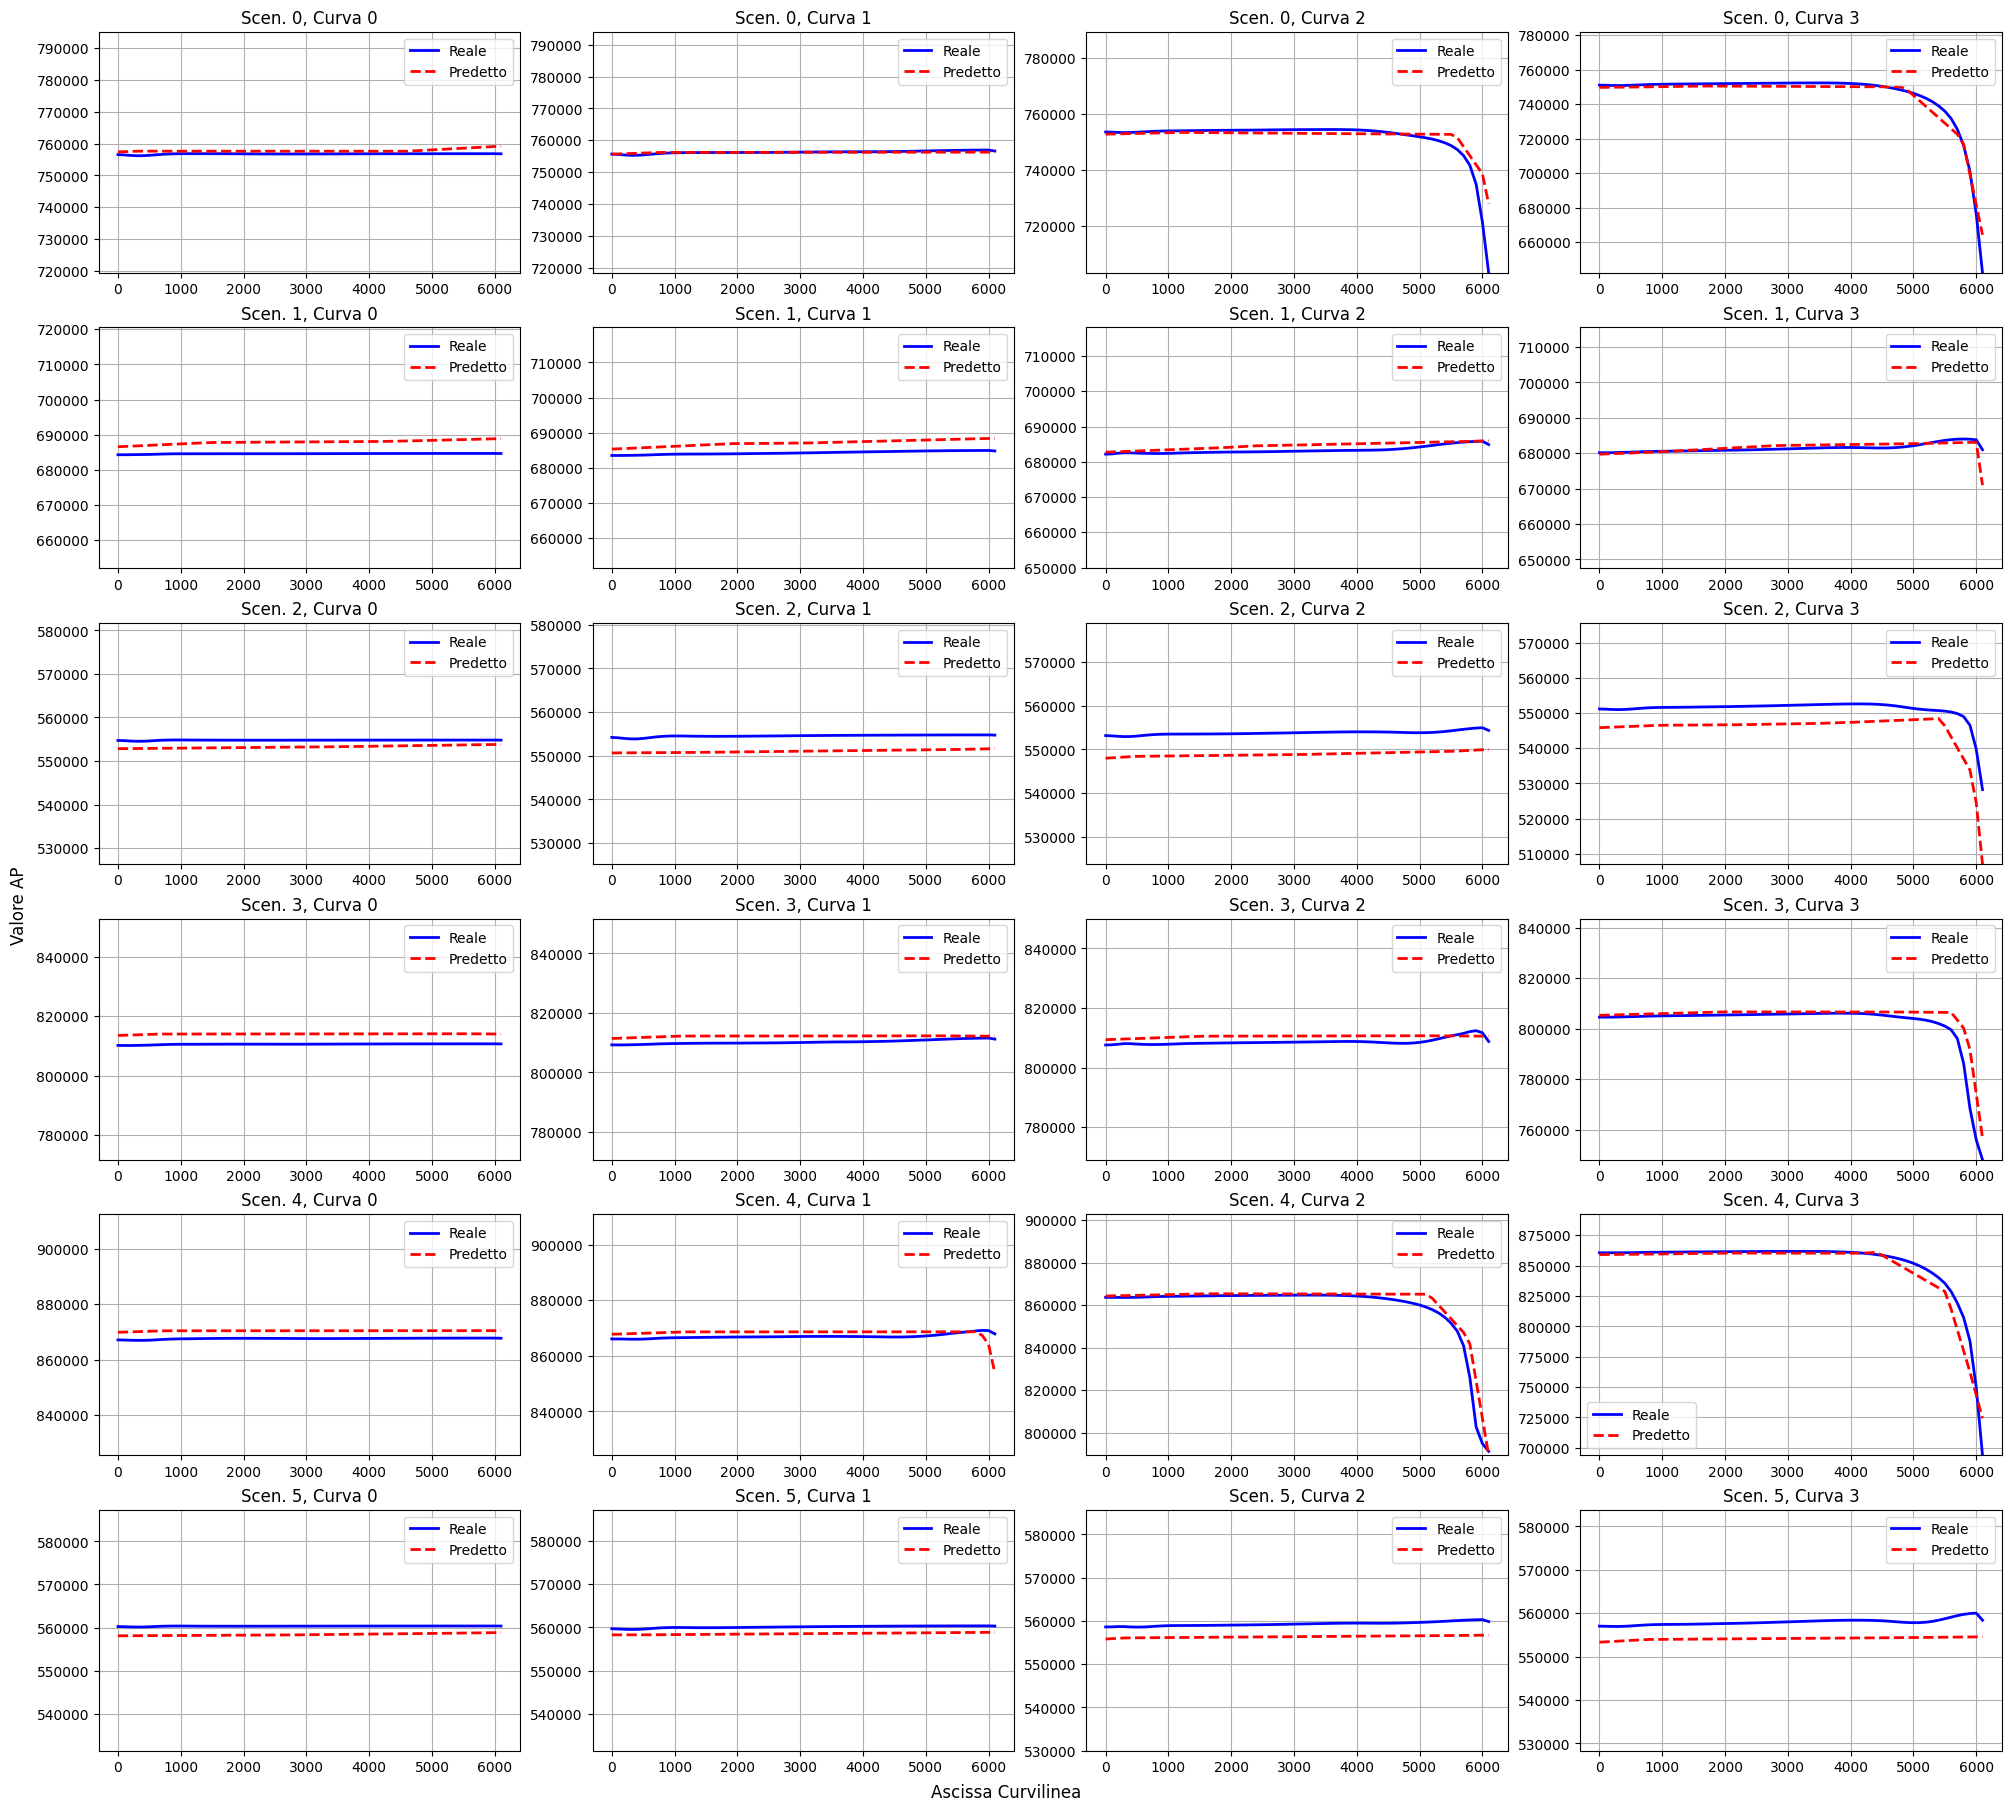

In [8]:
n_c = 4
n_abs = pipe_abs.shape[0]

# Riformattazione iniziale
ap_curves_flat = a_profiles
X_scalar_flat = X_data

# Ristrutturazione Dati
num_total_curves = X_scalar_flat.shape[0]
num_total_points = num_total_curves * n_abs
input_features_count = X_scalar_flat.shape[1] + 1
X_long = np.zeros((num_total_points, input_features_count))
y_long = np.zeros(num_total_points)

current_row = 0
for i in range(num_total_curves):
    scalar_features = X_scalar_flat[i, :]
    features_matrix = np.hstack([
        np.tile(scalar_features, (n_abs, 1)),
        pipe_abs.reshape(-1, 1)
    ])
    X_long[current_row : current_row + n_abs] = features_matrix
    y_long[current_row : current_row + n_abs] = ap_curves_flat[i, :]
    current_row += n_abs

# -Suddivisione Train-Validation-Test (basata su intere curve)
num_scenarios_in_test = 6
num_curves_in_test = num_scenarios_in_test * n_c
test_curve_indices = np.arange(num_curves_in_test)
train_val_curve_indices = np.arange(num_curves_in_test, num_total_curves)

train_val_mask = np.isin(np.floor(np.arange(num_total_points) / n_abs), train_val_curve_indices)
test_mask = np.isin(np.floor(np.arange(num_total_points) / n_abs), test_curve_indices)

X_train_val, y_train_val = X_long[train_val_mask], y_long[train_val_mask]
X_test, y_test = X_long[test_mask], y_long[test_mask]

# Creazione del set di validazione dal set di training
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

# Preprocessing e Creazione DataLoader
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) 
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32) 
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1) 
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

batch_size = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor) 
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size) 

# Costruzione del Modello MLP in PyTorch ------------------------------------------------------
class ProfileMLP(nn.Module):
    def __init__(self, input_features):
        super(ProfileMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.network(x)

model = ProfileMLP(input_features=X_train_scaled.shape[1])
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
print("Architettura del Modello:")
print(model)

# Addestramento del Modello ---------------------------------------------------------------
epochs = 100
best_val_loss = float('inf') 
best_model_state = None     
history = {'loss': [], 'val_loss': []} 

print("\nInizio Addestramento...")
for epoch in range(epochs):
    model.train()
    epoch_train_loss = 0.0
    for inputs, labels in train_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item()
    
    history['loss'].append(epoch_train_loss / len(train_loader))

    # BLOCCO DI VALIDAZIONE
    model.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            outputs_val = model(inputs_val)
            epoch_val_loss += criterion(outputs_val, labels_val).item()
    
    current_val_loss = epoch_val_loss / len(val_loader)
    history['val_loss'].append(current_val_loss)

    # Salva il modello migliore
    if current_val_loss < best_val_loss:
        best_val_loss = current_val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        # print(f'Epoca {epoch+1}: Nuovo best model salvato con val_loss: {best_val_loss:.4f}') 

    if (epoch + 1) % 10 == 0:
        print(f'Epoca [{epoch+1}/{epochs}], Training Loss: {history["loss"][-1]:.4f}, Validation Loss: {current_val_loss:.4f}')

# Valutazione e Metriche di Errore con il Modello Migliore -------------------------------------------------------
print("Caricamento del modello con il minor errore di validazione per la valutazione finale...")
model.load_state_dict(best_model_state) # Carica i pesi migliori
model.eval()

with torch.no_grad():
    y_pred_tensor = model(X_test_tensor)

y_pred = y_pred_tensor.cpu().numpy().flatten()
y_test_flat = y_test_tensor.cpu().numpy().flatten()

mse = mean_squared_error(y_test_flat, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_flat, y_pred)
r2 = r2_score(y_test_flat, y_pred)

print("\n--- Metriche di Errore sul Test Set (con modello ottimale) ---")
print(f"Mean Squared Error (MSE):       {mse:.4f}")
print(f"Root Mean Squared Error (RMSE):   {rmse:.4f}")
print(f"Mean Absolute Error (MAE):      {mae:.4f}")
print(f"Coefficiente R²:                {r2:.4f}")
print("-----------------------------------------")

# Visualizzazione dei Profili Predetti -----------------------------------------------------------------------------
num_scenarios_to_plot = 6
fig, axes = plt.subplots(num_scenarios_to_plot, n_c, figsize=(20, 18), layout="constrained", squeeze=False)

for scenario_idx in range(num_scenarios_to_plot):
    for curve_in_scenario_idx in range(n_c):
        ax = axes[scenario_idx, curve_in_scenario_idx]
        curve_idx = scenario_idx * n_c + curve_in_scenario_idx

        point_mask_in_test = (np.floor(np.arange(len(y_test)) / n_abs) == curve_idx)
        real_profile = y_test_flat[point_mask_in_test]
        predicted_profile = y_pred[point_mask_in_test]

        if real_profile.size > 0:
            combined_data = np.concatenate((real_profile, predicted_profile))
            data_mean = np.mean(combined_data)
            data_min = np.min(combined_data)
            data_max = np.max(combined_data)
            margin = abs(data_mean * 0.05)
            final_y_lower = min(data_mean - margin, data_min)
            final_y_upper = max(data_mean + margin, data_max)
            ax.set_ylim(final_y_lower, final_y_upper)

            ax.plot(pipe_abs, real_profile, label='Reale', linewidth=2, color='blue')
            ax.plot(pipe_abs, predicted_profile, label='Predetto', linestyle='--', linewidth=2, color='red')
            ax.legend()
        else:
            ax.text(0.5, 0.5, 'Training Set', ha='center', va='center', fontsize=12, alpha=0.5)
            ax.set_xticks([])
            ax.set_yticks([])

        ax.set_title(f"Scen. {scenario_idx}, Curva {curve_in_scenario_idx}")
        ax.grid(True)

fig.supxlabel("Ascissa Curvilinea")
fig.supylabel("Valore AP")
plt.show()